# 신규 사용자 추천 모델 비교

원본 서비스는 유지하고, 사용자 분리·프로필 고정·동일 후보 평가를 적용한 실험입니다. 최종 실행 결과는 `artifacts/cold_users_v2`에 저장합니다. 학습의 실제 구현은 `experiment.py`, 추천은 `predict.py`에 있습니다.

리뷰 작성자 데이터를 이용한 오프라인 대리 평가이며 구매·효능·안전성 평가가 아닙니다.

In [1]:
from pathlib import Path
import sys, json, subprocess

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "optimized" / "cold_start_benchmark").is_dir():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError("recommend_system 프로젝트 안에서 실행하세요.")
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))
from optimized.cold_start_benchmark.experiment import HERE, pd
RUN_DIR = HERE / "artifacts" / "cold_users_v2"
print("코드와 결과 위치:", HERE)
print("현재 커널:", sys.executable)


코드와 결과 위치: C:\Users\user\Desktop\recommend_system\optimized\cold_start_benchmark
현재 커널: C:\Users\user\AppData\Local\Programs\Python\Python311\python.exe


## 1. 데이터 정리와 사용자 분리

- 원본 분할본 5개만 사용하고 통합본과 전체 행 지문을 비교합니다.
- 같은 사용자–상품 리뷰는 가장 최근의 유효 리뷰를 남깁니다.
- 프로필은 가장 이른 유효 리뷰 시점에 고정합니다.
- 사용자 단위 70/15/15 분리이며 단일 리뷰 사용자도 유지합니다.
- 상품 전체 평점·리뷰 수와 리뷰 텍스트는 학습 입력에서 제외합니다.

In [2]:
summary = json.loads((RUN_DIR / "data_summary.json").read_text(encoding="utf-8"))
audit = json.loads((RUN_DIR / "source_audit.json").read_text(encoding="utf-8"))
print("행 지문 일치:", audit.get("merged_matches_parts"))
print("정제 리뷰:", summary["prepared_review_rows"])
print("사용자 분리:", summary["users_by_split"])
print("라벨 분포:", summary["labels"])


행 지문 일치: True
정제 리뷰: 1088886
사용자 분리: {'train': 352251, 'test': 75483, 'validation': 75482}
라벨 분포: {'1': 886770, '0': 166406, '-1': 35710}


## 2. 모델과 검증 기준

인기도·전체/피부타입별 베이지안 기준 모델, ID 없는 LightFM, 피부 타입 단독 LightFM, ID 포함 학습의 LightFM, CatBoost, LightGBM을 비교합니다. 트리는 관측된 긍정·부정을 사용하고 WARP는 긍정 리뷰를 사용합니다. LightGBM은 분류 모델입니다.

체크포인트와 최종 모델은 검증 데이터로 선택하고 테스트 데이터로 다시 고르지 않습니다. 아래 재학습 셀은 기본적으로 꺼져 있습니다. 완료한 실행을 덮어쓰지 않으므로 새 실행 이름을 사용하세요.

In [3]:
RUN_TRAINING = False
if RUN_TRAINING:
    subprocess.run([sys.executable, "-m", "optimized.cold_start_benchmark.run",
                    "--run-name", "cold_users_v3", "--lightfm-threads", "4"],
                   cwd=PROJECT_ROOT, check=True)
else:
    print("저장된 결과를 조회합니다. 재학습하려면 RUN_TRAINING을 True로 바꾸세요.")


저장된 결과를 조회합니다. 재학습하려면 RUN_TRAINING을 True로 바꾸세요.


## 3. 공통 테스트 결과

모든 모델의 테스트 사용자와 스킨케어 후보군은 같습니다. 표는 검증 NDCG@10 순서입니다. Recall·NDCG는 높을수록 좋고, 명시적 부정 상품의 추천 비율은 낮을수록 좋습니다. 미관측 상품의 만족도까지 알 수 있는 지표는 아닙니다.

In [4]:
comparison = pd.read_csv(RUN_DIR / "comparison.csv")
display(comparison.sort_values("validation_ndcg@10", ascending=False))
selection = json.loads((RUN_DIR / "selected_model.json").read_text(encoding="utf-8"))
print("검증으로 선택한 모델:", selection["model"])


검증으로 선택한 모델: lightfm_profile


,model,validation_ndcg@10,selected_by_validation,training_seconds,test_scoring_seconds,precision@10,recall@10,ndcg@10,hit_rate@10,known_negative@10,evaluated_users,unique_profiles,eligible_users,catalogue_coverage_at_10
3,lightfm_profile,0.089110,True,236.629558,0.341838,0.02178,0.133244,0.083878,0.1828,0.00097,10000,726,64294,0.030579
5,lightfm_identity_ablation,0.086866,False,282.834250,0.882089,0.02169,0.132621,0.082974,0.1812,0.00101,10000,726,64294,0.031818
4,lightfm_skin_only,0.065963,False,289.746614,0.332797,0.01690,0.102977,0.063258,0.1461,0.00078,10000,726,64294,0.010331
0,global_popularity,0.060294,False,0.000000,0.393794,0.01568,0.100556,0.058623,0.1381,0.00077,10000,726,64294,0.004132
2,skin_type_bayesian,0.007410,False,0.000000,0.565460,0.00378,0.014276,0.008557,0.0287,0.00006,10000,726,64294,0.010744
1,global_bayesian,0.007038,False,0.000000,0.422479,0.00357,0.016201,0.008802,0.0288,0.00009,10000,726,64294,0.004132
6,catboost,0.003038,False,263.532010,5.401102,0.00191,0.006208,0.003232,0.0150,0.00002,10000,726,64294,0.020661
7,lightgbm,0.001107,False,27.790950,18.857586,0.00100,0.003393,0.001639,0.0079,0.00003,10000,726,64294,0.011983


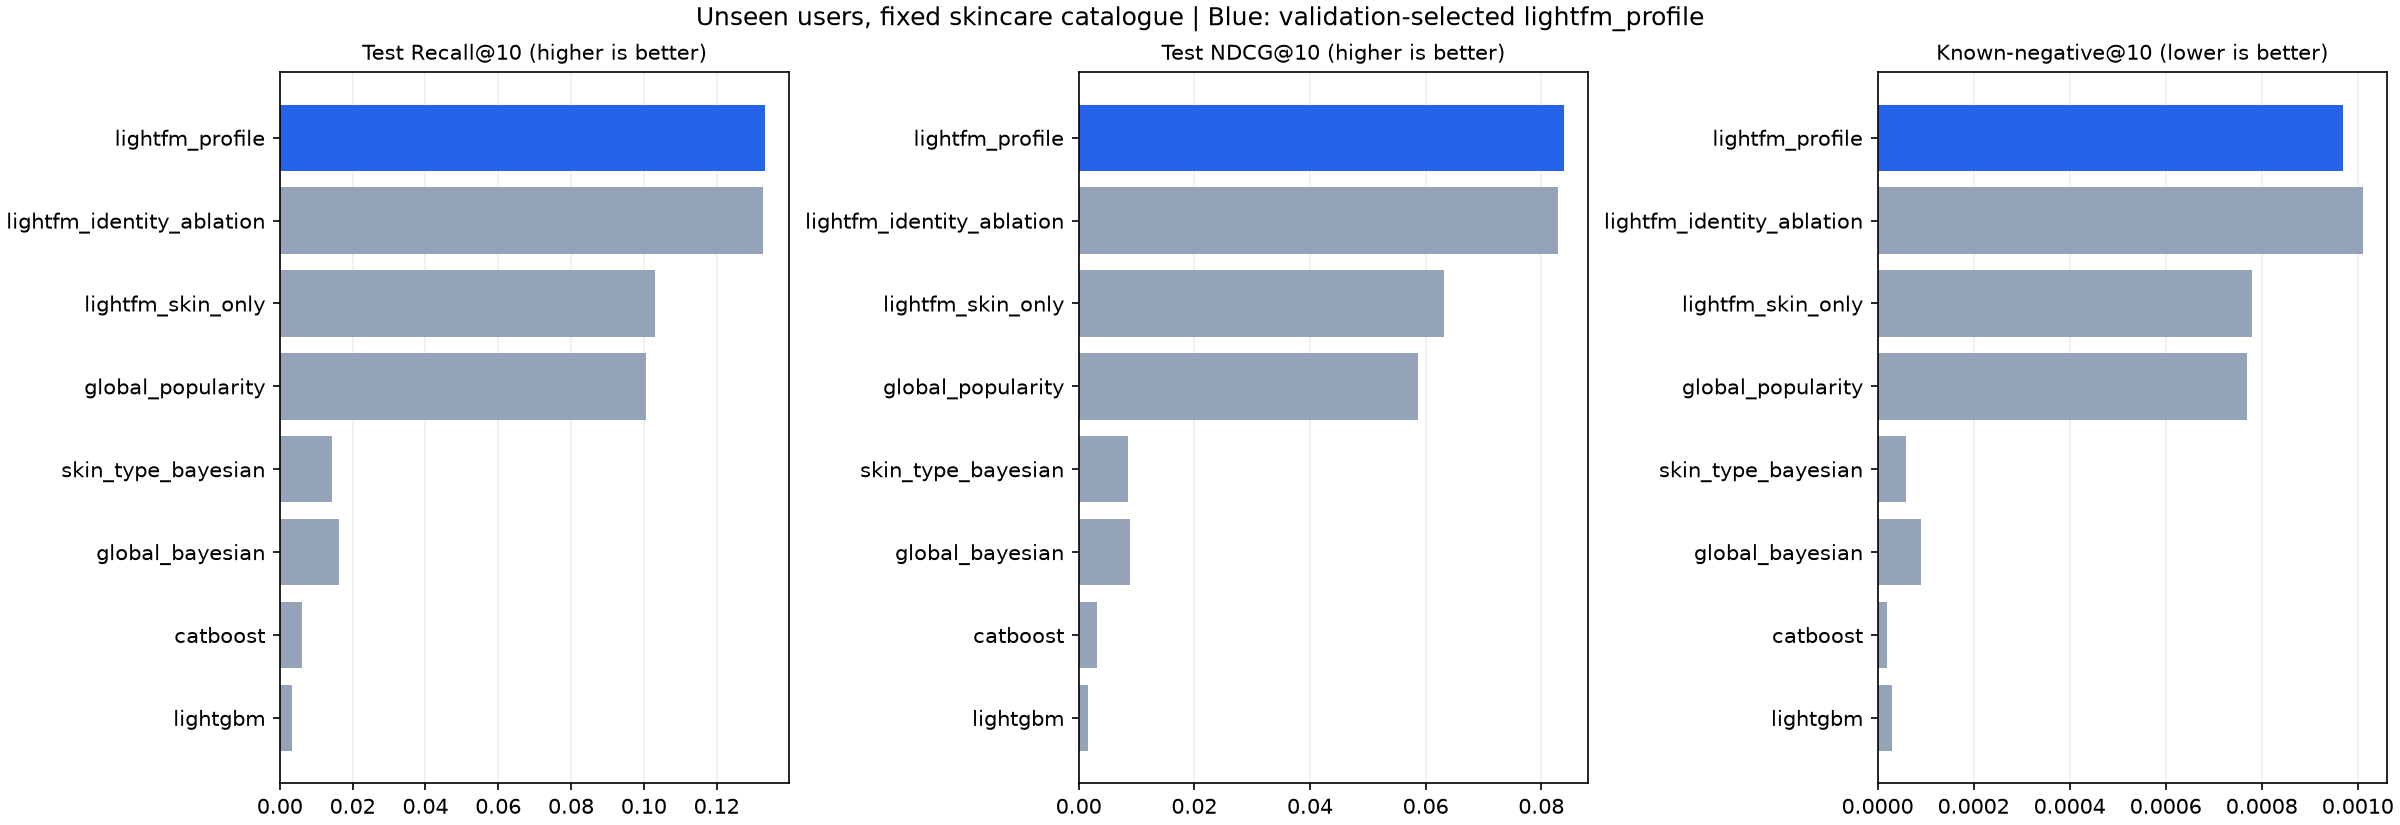

In [5]:
from IPython.display import Image, display
if (RUN_DIR / "comparison.png").exists():
    display(Image(filename=str(RUN_DIR / "comparison.png")))


## 4. 사용자별 차이와 피부 타입별 결과

단일 seed의 학습이므로 모델 재학습 변동성까지 확인한 실험은 아닙니다. paired bootstrap은 같은 테스트 사용자에서 모델 점수 차이의 불확실성을 확인합니다.

In [6]:
display(pd.DataFrame(json.loads((RUN_DIR / "paired_uncertainty.json").read_text(encoding="utf-8"))))
selected_name = selection["model"]
display(pd.read_csv(RUN_DIR / f"{selected_name}_by_skin.csv"))


,selected,against,ndcg_difference,paired_bootstrap_95ci
0,lightfm_profile,global_popularity,0.025255,"[0.022463395933211377, 0.028169905040166983]"
1,lightfm_profile,global_bayesian,0.075075,"[0.07095195775346365, 0.07930671449635766]"
2,lightfm_profile,skin_type_bayesian,0.075321,"[0.0715860252793517, 0.07944068302173589]"
3,lightfm_profile,lightfm_profile,0.000000,"[0.0, 0.0]"
4,lightfm_profile,lightfm_skin_only,0.020620,"[0.01781567976625463, 0.023115808275332817]"
5,lightfm_profile,lightfm_identity_ablation,0.000904,"[-5.395724850487975e-05, 0.0018683935578020668]"
6,lightfm_profile,catboost,0.080646,"[0.07677876863067637, 0.08469235630741251]"
7,lightfm_profile,lightgbm,0.082239,"[0.0783170810005484, 0.08636435799879566]"


,skin_type,precision@10,recall@10,ndcg@10,hit_rate@10,known_negative@10
0,combination,0.019919,0.117821,0.072759,0.163108,0.001003
1,dry,0.019739,0.129028,0.084993,0.168627,0.000915
2,normal,0.021162,0.125252,0.085979,0.167635,0.001245
3,oily,0.023557,0.130611,0.087676,0.183426,0.000931
4,unknown,0.028865,0.193728,0.112919,0.270073,0.000730


## 5. 저장 모델로 신규 프로필 추천

사용자 ID와 과거 리뷰 없이 실행합니다. 제품 종류는 현재 영문 부분 문자열 필터입니다. 표시되는 점수는 효능·피부 적합성 확률이 아닙니다.

In [7]:
from optimized.cold_start_benchmark.predict import recommend
result = recommend(RUN_DIR, {"skin_type": "dry", "skin_tone": "unknown",
                             "eye_color": "unknown", "hair_color": "unknown"},
                   top_k=5, product_type="serum")
print(result["model"], result["profile_used"])
display(pd.DataFrame(result["recommendations"]))


lightfm_profile {'skin_type': 'dry', 'skin_tone': 'unknown', 'eye_color': 'unknown', 'hair_color': 'unknown'}


,product_id,product_name,brand_name,price_usd,ranking_score
0,P309308,Good Genes All-In-One AHA Lactic Acid Treatment,Sunday Riley,122.0,-126.650185
1,P384780,Pure Argan Milk Intensive Hydrating Treatment,Josie Maran,56.0,-126.860481
2,P94421,Vinoperfect Radiance Dark Spot Serum Vitamin C...,Caudalie,82.0,-126.931717
3,P392246,T.L.C. Framboos Glycolic Resurfacing Night Serum,Drunk Elephant,90.0,-127.030548
4,P406712,B-Hydra Intensive Hydration Serum with Hyaluro...,Drunk Elephant,49.0,-127.366096


## 6. 원래 노트북 설정과 같은 평가로 비교

원래 보고된 무작위 리뷰 분할 점수와 신규 사용자 점수는 직접 비교할 수 없습니다. 원래 설정(64차원, ID 포함, 원래 feature와 k-core)을 공통 학습 사용자로 재학습한 결과를 별도로 확인합니다. 이전 표의 `lightfm_identity_ablation`은 원본 재현 모델이 아닙니다.

원래 기록된 수치: 다른 평가 조건이므로 아래 표와 직접 개선율을 계산하지 않습니다.
동일 신규 사용자 10,000명으로 직접 비교:


,precision@10,recall@10,auc
baseline_20_epochs,0.015545,0.110722,0.854744
tuned_30_epochs,0.017057,0.118033,0.865102


,model,precision@10,recall@10,ndcg@10
0,original_notebook_20_epochs,0.01861,0.099186,0.060355
1,original_notebook_30_epochs,0.01933,0.104411,0.062001
2,lightfm_profile,0.02178,0.133244,0.083878


,original_model,ndcg_difference,ndcg_difference_95ci
0,original_notebook_20_epochs,0.023523,"[0.02081372913971393, 0.02631317749664795]"
1,original_notebook_30_epochs,0.021877,"[0.01923600247181204, 0.024579087998740805]"


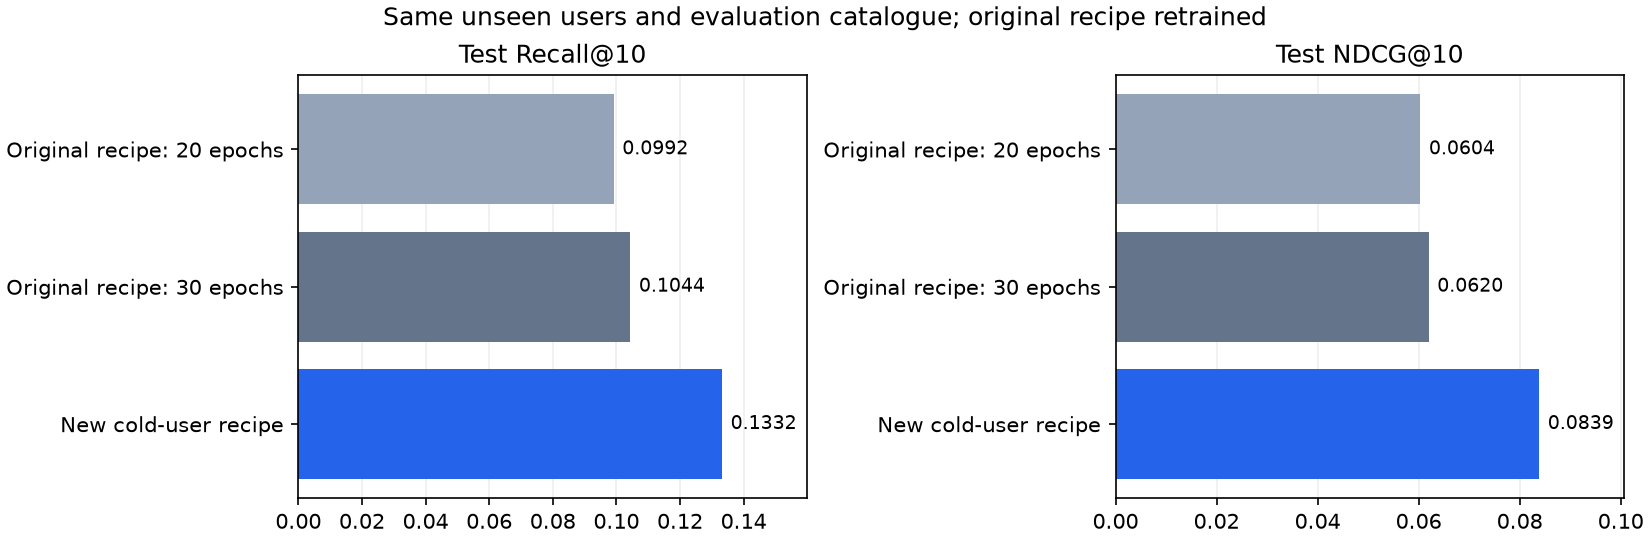

In [8]:
original_dir = HERE / "artifacts" / "original_same_users_v1"
reference = json.loads((HERE / "original_notebook_reference.json").read_text(encoding="utf-8"))
print("원래 기록된 수치: 다른 평가 조건이므로 아래 표와 직접 개선율을 계산하지 않습니다.")
display(pd.DataFrame(reference["historical_random_split_metrics"]).T)
print("동일 신규 사용자 10,000명으로 직접 비교:")
original_comparison = pd.read_csv(original_dir / "comparison.csv")
display(original_comparison[["model", "precision@10", "recall@10", "ndcg@10"]])
display(pd.DataFrame(json.loads((original_dir / "paired_comparison.json").read_text(encoding="utf-8"))))
if (original_dir / "original_comparison.png").exists():
    display(Image(filename=str(original_dir / "original_comparison.png")))


## 7. 다음 실험

1. 여러 사용자 분리 seed에서 반복 평가
2. 사용자 분리와 시간 경계를 동시에 적용한 평가
3. 실제 요청의 제품 종류·성분 필터 이후 순위 평가
4. 입력 프로필이 부족한 사용자와 피부 타입별 표본 수 확인
5. 서비스 로그가 쌓이면 구매·저장·클릭 지표로 검증

새 평가 조건을 설계할 때 기존 테스트 결과를 반복적인 튜닝 기준으로 사용하지 않습니다.